# Análisis exploratorio — Diabetes 130-US hospitals (1999-2008)

Este notebook justifica las decisiones de limpieza, ingeniería de características,
partición y selección de métrica que implementa el paquete compartido
`ml/diabetes_model` (transformación `readmission-features-v2`) y que el DAG
`diabetes_incremental_training` aplica sobre la capa RAW.

**Problema:** predecir, al momento del alta, si el paciente será readmitido en
menos de 30 días (`<30`), después de 30 días (`>30`) o no será readmitido (`NO`).

Requisito: el dataset debe existir en `data/Diabetes/Diabetes.csv`
(`python3 scripts/download_diabetes_dataset.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from diabetes_model.contract import (
    EXCLUDED_DISCHARGE_IDS,
    INPUT_COLUMNS,
    MEDICATION_COLUMNS,
    NUMERIC_INPUTS,
    exclusion_reason,
    input_frame,
)
from diabetes_model.features import FEATURE_COLUMNS, engineer_features, icd9_group, specialty_group
from diabetes_model.splits import assign_split

pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (9, 4)

DATA_PATH = next(
    path for path in (Path("data/Diabetes/Diabetes.csv"), Path("../data/Diabetes/Diabetes.csv"))
    if path.exists()
)
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f"{raw.shape[0]:,} encuentros x {raw.shape[1]} columnas")
raw.head(3)

101,766 encuentros x 50 columnas


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


## 1. Variable objetivo

La clase `<30` (la más relevante clínicamente) representa solo ~11% de los
encuentros. Un modelo que prediga siempre `NO` tendría ~54% de *accuracy* y
cero utilidad, por lo que **accuracy no sirve como métrica de selección**.

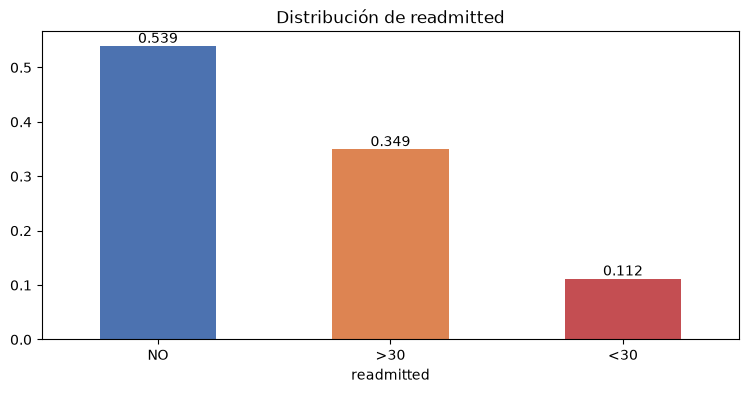

,proporción
readmitted,
NO,0.539119
>30,0.349282
<30,0.111599


In [2]:
target_share = raw["readmitted"].value_counts(normalize=True).rename("proporción")
ax = target_share.plot.bar(color=["#4C72B0", "#DD8452", "#C44E52"], rot=0, title="Distribución de readmitted")
ax.bar_label(ax.containers[0], fmt="%.3f")
plt.show()
target_share.to_frame()

**Decisión de métrica:** se usa **macro-F1 en validación** como métrica principal.
Promedia el F1 de las tres clases con el mismo peso, de modo que el modelo no
puede obtener buen puntaje ignorando `<30` y `>30`. Como métricas secundarias
se registran el recall por clase (en especial `<30`, porque un falso negativo
es un paciente de alto riesgo enviado a casa sin seguimiento), ROC-AUC
one-vs-rest y *balanced accuracy*. Todos los candidatos usan pesos de clase
balanceados.

## 2. Valores faltantes

El dataset codifica los faltantes como `?`. Además, en `max_glu_serum` y
`A1Cresult` el valor `None` **no es un faltante**: significa que la prueba no se
realizó, y es informativo.

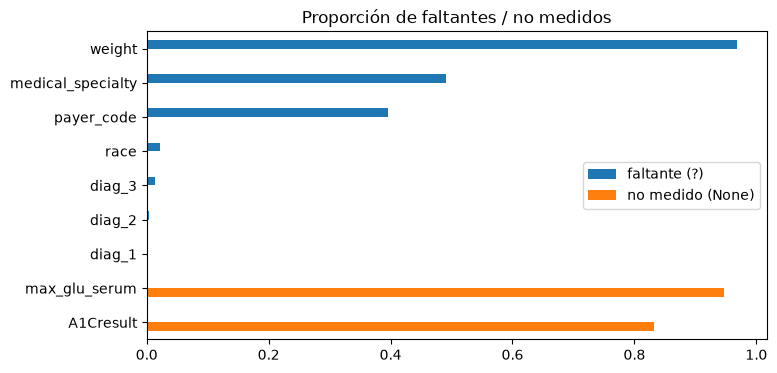

,faltante (?),no medido (None)
weight,0.9686,0.0000
medical_specialty,0.4908,0.0000
payer_code,0.3956,0.0000
race,0.0223,0.0000
diag_3,0.0140,0.0000
diag_2,0.0035,0.0000
diag_1,0.0002,0.0000
max_glu_serum,0.0000,0.9475
A1Cresult,0.0000,0.8328


In [3]:
missing = (raw == "?").mean().rename("faltante (?)")
not_measured = (raw[["max_glu_serum", "A1Cresult"]] == "None").mean().rename("no medido (None)")
summary = pd.concat([missing, not_measured], axis=1).fillna(0)
summary = summary[(summary > 0).any(axis=1)].sort_values("faltante (?)", ascending=False)
summary.plot.barh(title="Proporción de faltantes / no medidos", figsize=(8, 4))
plt.gca().invert_yaxis()
plt.show()
summary.round(4)

**Decisiones:**
- `weight` se elimina: 96,9% faltante.
- `payer_code` (39,6%) y `medical_specialty` (49,1%) se conservan; el faltante se
  imputa como la categoría explícita `__missing__`, porque la ausencia de
  registro puede correlacionar con el tipo de atención.
- `race` y los diagnósticos tienen pocos faltantes: categoría `__missing__`.
- `None` en `max_glu_serum`/`A1Cresult` se mantiene como categoría "no medido".
- Las variables numéricas no tienen faltantes en la fuente; en el modelo se
  imputa la mediana del *train* por robustez frente a entradas de la API.

## 3. Cardinalidad, columnas constantes y medicamentos raros

Columnas con un solo valor: ['examide', 'citoglipton']


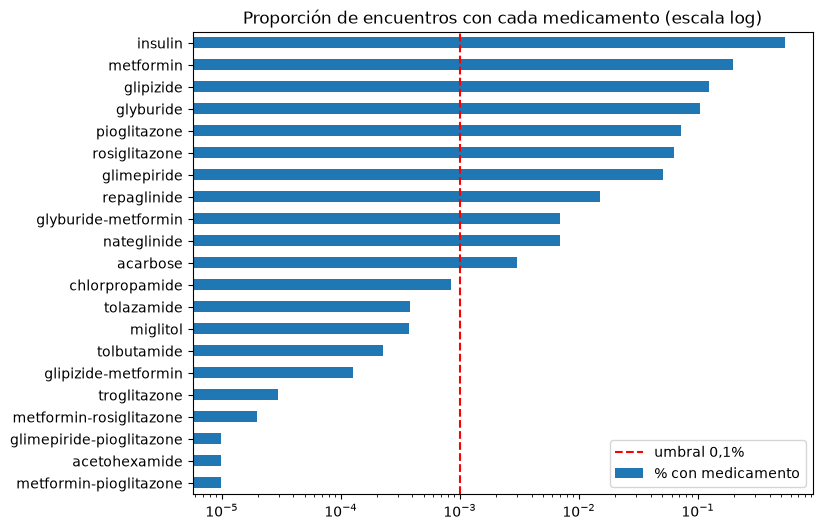

,% con medicamento
metformin-pioglitazone,0.0010%
acetohexamide,0.0010%
glimepiride-pioglitazone,0.0010%
metformin-rosiglitazone,0.0020%
troglitazone,0.0029%
glipizide-metformin,0.0128%
tolbutamide,0.0226%
miglitol,0.0373%
tolazamide,0.0383%
chlorpropamide,0.0845%


In [4]:
cardinality = raw.nunique().sort_values()
print("Columnas con un solo valor:", list(cardinality[cardinality == 1].index))
treated_share = {
    column: (raw[column] != "No").mean() for column in MEDICATION_COLUMNS
}
treated = pd.Series(treated_share, name="% con medicamento").sort_values()
treated.plot.barh(logx=True, title="Proporción de encuentros con cada medicamento (escala log)", figsize=(8, 6))
plt.axvline(0.001, color="red", linestyle="--", label="umbral 0,1%")
plt.legend()
plt.show()
treated.map("{:.4%}".format).to_frame()

**Decisiones:**
- `examide` y `citoglipton` se eliminan (un único valor).
- Los 10 medicamentos usados en menos del 0,1% de los encuentros (≤ 90 casos)
  no se usan como columnas individuales: no aportan señal estable y agregan
  ruido. Su información se conserva en dos variables agregadas:
  `num_active_medications` (medicamentos activos) y `num_medication_changes`
  (dosis aumentadas o reducidas).

## 4. Pacientes con múltiples encuentros → partición por paciente

Hay pacientes con varios encuentros. Si el mismo paciente aparece en *train* y
en *test*, el modelo "memoriza" al paciente y la métrica se infla (fuga de
información).

In [5]:
encounters = raw["patient_nbr"].value_counts()
print(f"Pacientes únicos: {encounters.size:,}")
print(f"Pacientes con más de un encuentro: {(encounters > 1).sum():,} "
      f"({(encounters > 1).mean():.1%}), que suman {encounters[encounters > 1].sum():,} encuentros")
encounters.clip(upper=10).value_counts().sort_index().rename("pacientes").to_frame().T

Pacientes únicos: 71,518
Pacientes con más de un encuentro: 16,773 (23.5%), que suman 47,021 encuentros


count,1,2,3,4,5,6,7,8,9,10
pacientes,54745,10434,3328,1421,717,346,207,111,70,139


**Decisión:** la partición se asigna con un hash SHA-256 (con *salt*) de
`patient_nbr`: 70% *train*, 15% *validation*, 15% *test*. Como solo depende
del paciente:
- todos los encuentros de un paciente quedan en la misma partición;
- la asignación es estable cuando los datos llegan por lotes (un paciente del
  lote 1 y del lote 6 cae en la misma partición sin recalcular nada).

## 5. Disposición al alta: pacientes fallecidos y en hospicio

Los códigos 11, 19, 20 y 21 significan que el paciente falleció, y 13 y 14 que
fue dado de alta a hospicio. Un paciente fallecido no puede ser readmitido, así
que su etiqueta `NO` no describe el riesgo de readmisión.

In [6]:
discharge = pd.crosstab(raw["discharge_disposition_id"], raw["readmitted"])
excluded = discharge.loc[discharge.index.isin(EXCLUDED_DISCHARGE_IDS)]
print(f"Encuentros excluidos: {excluded.values.sum():,}")
excluded

Encuentros excluidos: 2,423


readmitted,<30,>30,NO
discharge_disposition_id,,,
11,0,0,1642
13,19,36,344
14,24,7,341
19,0,0,8
20,0,0,2


**Decisión:** estos encuentros se excluyen del entrenamiento (quedan en CLEAN
con `exclusion_reason = 'discharged_expired_or_hospice'` para trazabilidad).
`discharge_disposition_id` sí se usa como variable: la predicción se hace **al
momento del alta**, cuando el destino del paciente ya se conoce, y el destino
(casa, casa con atención domiciliaria, traslado a otra institución, alta
voluntaria) se relaciona con el riesgo de readmisión.

## 6. Variables numéricas

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


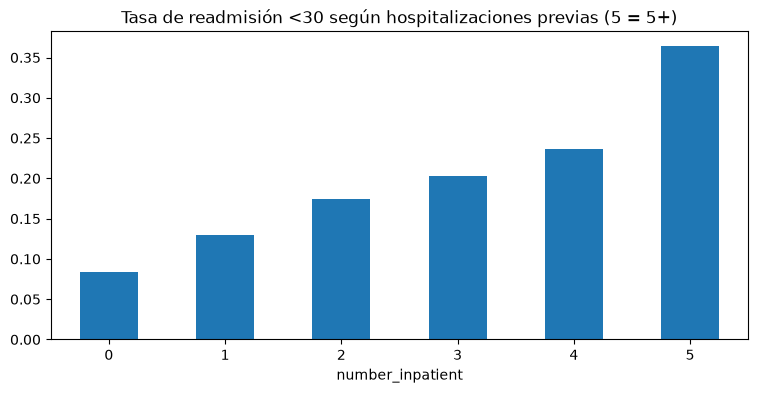

In [7]:
numeric = raw[list(NUMERIC_INPUTS)].astype(int)
display(numeric.describe().T.round(2))
rates = (
    raw.assign(readmitted_lt30=raw["readmitted"].eq("<30"),
               number_inpatient=numeric["number_inpatient"].clip(upper=5))
    .groupby("number_inpatient")["readmitted_lt30"].mean()
)
rates.plot.bar(rot=0, title="Tasa de readmisión <30 según hospitalizaciones previas (5 = 5+)")
plt.show()

Las hospitalizaciones previas son la señal más fuerte: la tasa de readmisión
temprana crece de forma monótona. Se agrega `total_visits` (ambulatorias +
urgencias + hospitalizaciones del año anterior) como medida de uso del sistema
de salud. Las numéricas se estandarizan para la regresión logística; los
modelos de árboles las usan sin escalar.

## 7. Edad

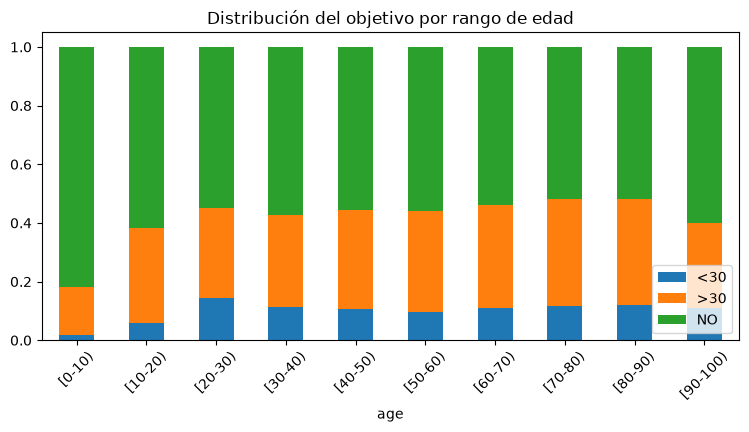

In [8]:
age_rates = pd.crosstab(raw["age"], raw["readmitted"], normalize="index")[["<30", ">30", "NO"]]
age_rates.plot.bar(stacked=True, rot=45, title="Distribución del objetivo por rango de edad")
plt.legend(loc="lower right")
plt.show()

**Decisión:** el rango de edad es ordinal; se convierte a `age_years` (punto
medio del rango: 5, 15, …, 95). Así los modelos aprovechan el orden en vez de
tratar 10 categorías independientes.

## 8. Diagnósticos (ICD-9) y especialidad

In [9]:
print({column: raw[column].nunique() for column in ("diag_1", "diag_2", "diag_3", "medical_specialty")})
groups = raw["diag_1"].map(icd9_group).fillna("missing")
diag_rates = (
    pd.crosstab(groups, raw["readmitted"], normalize="index")["<30"].sort_values()
)
diag_counts = groups.value_counts()
pd.DataFrame({"encuentros": diag_counts, "tasa <30": diag_rates}).sort_values("encuentros", ascending=False).round(3)

{'diag_1': 717, 'diag_2': 749, 'diag_3': 790, 'medical_specialty': 73}


,encuentros,tasa <30
diag_1,,
circulatory,30437,0.114
other,18172,0.115
respiratory,14423,0.097
digestive,9475,0.107
diabetes,8757,0.130
injury,6974,0.122
genitourinary,5117,0.108
musculoskeletal,4957,0.095
neoplasms,3433,0.101


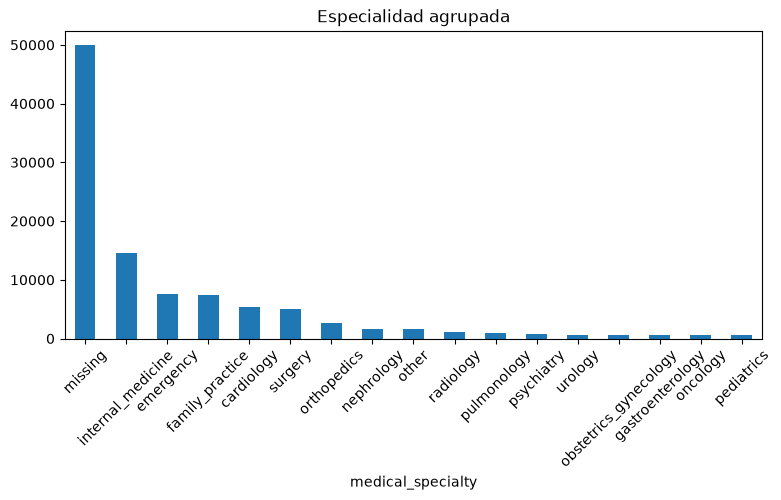

In [10]:
specialties = raw["medical_specialty"].map(specialty_group).fillna("missing")
specialties.value_counts().plot.bar(rot=45, title="Especialidad agrupada")
plt.show()

**Decisiones:**
- Los diagnósticos tienen 700-790 códigos distintos cada uno. Con *one-hot*
  generan miles de columnas dispersas, muchas con muy pocos casos. Se agrupan
  en los capítulos ICD-9 usados por Strack et al. (2014) para este dataset:
  circulatorio, respiratorio, digestivo, diabetes (250.xx), lesiones,
  musculoesquelético, genitourinario, neoplasias y otros (incluye códigos V/E).
- `medical_specialty` (72 valores) se agrupa en especialidades frecuentes
  (medicina interna, urgencias, cardiología, cirugía, …) más `other`.
- `admission_type_id`, `admission_source_id` y `discharge_disposition_id` son
  códigos sin orden numérico: se agrupan en categorías con significado
  (urgencia/electiva, remisión/urgencias/traslado, casa/traslado/…), y los
  códigos de "desconocido/NULL" van a `unknown`.

## 9. Resultado de la transformación `readmission-features-v2`

In [11]:
eligible = raw[raw.apply(lambda row: exclusion_reason(row) is None, axis=1)]
features = engineer_features(input_frame(eligible.to_dict(orient="records")))
print(f"Entradas del contrato (API): {len(INPUT_COLUMNS)} | Variables del modelo: {len(FEATURE_COLUMNS)}")
print(f"Encuentros elegibles: {len(features):,} de {len(raw):,}")
features.head()

Entradas del contrato (API): 44 | Variables del modelo: 37
Encuentros elegibles: 99,343 de 101,766


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age_years,total_visits,num_active_medications,num_medication_changes,race,gender,payer_code,medical_specialty_group,admission_type,admission_source,discharge_group,diag_1_group,diag_2_group,diag_3_group,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,insulin,glyburide-metformin,change,diabetesMed
0,1.0,41.0,0.0,1.0,0.0,0.0,0.0,1.0,5.0,0.0,0.0,0.0,Caucasian,Female,NaN,pediatrics,unknown,referral,unknown,diabetes,NaN,NaN,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No
1,3.0,59.0,0.0,18.0,0.0,0.0,0.0,9.0,15.0,0.0,1.0,1.0,Caucasian,Female,NaN,NaN,emergency,emergency_room,home,other,diabetes,other,None,None,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes
2,2.0,11.0,5.0,13.0,2.0,0.0,1.0,6.0,25.0,3.0,1.0,0.0,AfricanAmerican,Female,NaN,NaN,emergency,emergency_room,home,other,diabetes,other,None,None,No,No,No,No,Steady,No,No,No,No,No,No,No,Yes
3,2.0,44.0,1.0,16.0,0.0,0.0,0.0,7.0,35.0,0.0,1.0,1.0,Caucasian,Male,NaN,NaN,emergency,emergency_room,home,other,diabetes,circulatory,None,None,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes
4,1.0,51.0,0.0,8.0,0.0,0.0,0.0,5.0,45.0,0.0,2.0,0.0,Caucasian,Male,NaN,NaN,emergency,emergency_room,home,neoplasms,neoplasms,diabetes,None,None,No,No,No,No,Steady,No,No,No,No,Steady,No,Ch,Yes


## 10. Verificación de la partición

In [12]:
split = eligible["patient_nbr"].map(assign_split)
split_table = pd.crosstab(split, eligible["readmitted"], normalize="index").round(3)
split_table["filas"] = split.value_counts()
split_table["% filas"] = (split.value_counts(normalize=True)).round(3)
assert eligible.assign(split=split).groupby("patient_nbr")["split"].nunique().max() == 1
split_table

readmitted,<30,>30,NO,filas,% filas
patient_nbr,,,,,
test,0.109,0.351,0.540,14771,0.149
train,0.115,0.358,0.528,69586,0.700
validation,0.115,0.362,0.523,14986,0.151


Las tres particiones tienen ~70/15/15% de las filas y una distribución de clases
casi idéntica, sin pacientes compartidos (la aserción lo verifica).

## 11. Comparación de candidatos (mismo procedimiento que el DAG)

Se entrenan tres familias de modelos sobre *train* y se comparan en
*validation*. El conjunto *test* solo se reporta y no se usa para seleccionar.

In [13]:
from diabetes_model.training import best_candidate, prepare_dataset, train_candidates

dataset = prepare_dataset(DATA_PATH)
results = train_candidates(dataset)
comparison = pd.DataFrame({name: metrics for name, (_, metrics) in results.items()}).T
columns = [
    "train_macro_f1", "validation_macro_f1", "test_macro_f1",
    "validation_recall_readmitted_within_30_days", "validation_roc_auc_ovr_macro",
    "validation_balanced_accuracy",
]
print("Mejor candidato por validation_macro_f1:", best_candidate(results))
comparison[columns].round(4).sort_values("validation_macro_f1", ascending=False)

Mejor candidato por validation_macro_f1: hist_gradient_boosting


,train_macro_f1,validation_macro_f1,test_macro_f1,validation_recall_readmitted_within_30_days,validation_roc_auc_ovr_macro,validation_balanced_accuracy
hist_gradient_boosting,0.4974,0.4413,0.4409,0.4287,0.6652,0.4675
logistic_regression,0.4344,0.4317,0.4279,0.4304,0.6540,0.4594
random_forest,0.4672,0.4276,0.4316,0.4560,0.6617,0.4606


## 12. Resumen de decisiones

| Tema | Decisión | Evidencia |
|---|---|---|
| Objetivo | 3 clases (`NO`, `>30`, `<30`) | §1 |
| Métrica principal | macro-F1 de validación; recall de `<30` y ROC-AUC como apoyo | §1, §11 |
| Desbalance | `class_weight` balanceado en todos los candidatos | §1 |
| `weight` | eliminada (96,9% faltante) | §2 |
| `examide`, `citoglipton` | eliminadas (constantes) | §3 |
| 10 medicamentos raros | solo en conteos agregados | §3 |
| Faltantes categóricos | categoría `__missing__` | §2 |
| `None` en laboratorios | categoría "no medido" | §2 |
| Fallecidos/hospicio | excluidos del entrenamiento | §5 |
| Partición | hash de paciente 70/15/15, estable entre lotes | §4, §10 |
| Edad | ordinal `age_years` | §7 |
| Diagnósticos | capítulos ICD-9 | §8 |
| Especialidad / códigos | agrupación por significado clínico | §8 |
| Nuevas variables | `total_visits`, `num_active_medications`, `num_medication_changes` | §3, §6 |